# $120^\circ$ Néel spin structure

In [9]:
using Random: MersenneTwister
using MX2RKKY

using PyPlot; const plt = PyPlot;
plt.pygui(false); plt.svg(true);

In [7]:
# Cluster size
L1, L2 = 25, 25
N = L1 * L2

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0

# RKKY parameters
Vperp = 0.0
λ = 0.1; # k_F a_0

# $V_\parallel = 0$

In [8]:
Vpar = 0.0

# Temperature scan
T_range = 0.2:0.2:4.0

n_cycles = 2000
n_warmup_cycles = 100
cycle_length = 50

χ_avg = []
χ_var = []

for T in T_range
    rng = MersenneTwister(123456)
    conf = Configuration(L1, L2, rng, inplane=true)
    sim = MCSimulation(conf, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
    run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)

    @show T
    @show acceptance_rates(sim)
    @show avg_chirality(sim)
    @show var_chirality(sim)

    push!(χ_avg, avg_chirality(sim))
    push!(χ_var, var_chirality(sim))
end

Running MC simulation 100%|██████████████████████████████| Time: 0:05:14


T = 0.2
acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.11240989674654199, MX2RKKY.UpdateSingleSpin{true} => 0.16004813477737664)
avg_chirality(sim) = -0.09815520000000007
var_chirality(sim) = 0.03837267664575769


Running MC simulation 100%|██████████████████████████████| Time: 0:05:00


T = 0.4
acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.15643733942335142, MX2RKKY.UpdateSingleSpin{true} => 0.2412187404091395)
avg_chirality(sim) = 0.3448544000000007
var_chirality(sim) = 0.12086930826574238


Running MC simulation 100%|██████████████████████████████| Time: 0:05:03


T = 0.6
acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.21956973013776185, MX2RKKY.UpdateSingleSpin{true} => 0.33375352217114046)
avg_chirality(sim) = 0.04245760000000005
var_chirality(sim) = 0.06374635144257303


... (30 outputs left out)

Running MC simulation 100%|██████████████████████████████| Time: 0:05:15


T = 3.8
acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.7161808669656203, MX2RKKY.UpdateSingleSpin{true} => 0.7978281157207092)
avg_chirality(sim) = 0.0005040000000000044
var_chirality(sim) = 0.02530640519710373


Running MC simulation 100%|██████████████████████████████| Time: 0:05:16


T = 4.0
acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.7340445619335347, MX2RKKY.UpdateSingleSpin{true} => 0.8037348529785612)
avg_chirality(sim) = 0.0008552000000000012
var_chirality(sim) = 0.024093089319553836


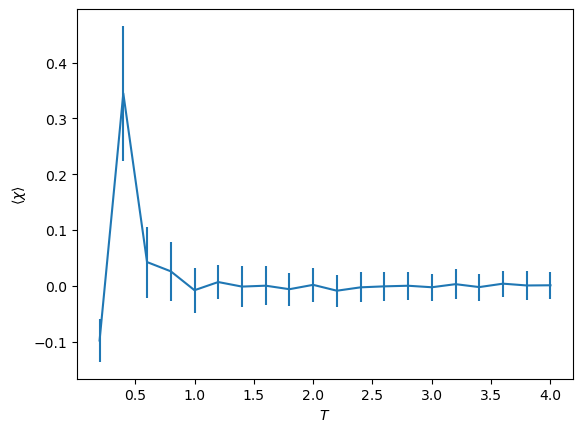

PyObject Text(28.0, 0.5, '$\\langle\\chi\\rangle$')

In [14]:
plt.errorbar(collect(T_range), χ_avg, yerr=χ_var)
plt.xlabel(raw"$T$")
plt.ylabel(raw"$\langle\chi\rangle$")

In [50]:
function plot_conf(conf::MX2RKKY.Configuration, plot_scale::Float64 = 0.5)
    i2c = (i1, i2) -> (i1 - 0.5 * i2, √3/2 * i2)
    L1, L2 = size(conf)

    # Draw triangular grid
    grid_segments = []
    for i1 in 0:(L1-1)
        push!(grid_segments, [i2c(i1, 0), i2c(i1, L2-1)])
        (i1 == L1-1) && continue
        lenc = L1-i1-1
        push!(grid_segments, [i2c(i1, 0), i2c(i1, 0) .+ i2c(lenc, lenc)])
    end
    for i2 in 0:(L2-1)
        push!(grid_segments, [i2c(0, i2), i2c(L1-1, i2)])
        (i2 == 0 || i2 == L2-1) && continue
        lenc = min(L2-i2-1, L1-1)
        push!(grid_segments, [i2c(0, i2), i2c(0, i2) .+ i2c(lenc, lenc)])
    end
    grid = plt.matplotlib.collections.LineCollection(grid_segments, linewidths=0.5)

    xmin = minimum(min(s[1][1], s[2][1]) for s in grid_segments)
    xmax = maximum(max(s[1][1], s[2][1]) for s in grid_segments)
    ymin = minimum(min(s[1][2], s[2][2]) for s in grid_segments)
    ymax = maximum(max(s[1][2], s[2][2]) for s in grid_segments)
    
    fig = plt.figure(figsize=(plot_scale * (xmax-xmin), plot_scale * (ymax-ymin)))
    ax = plt.gca()
    ax.add_collection(grid)
    
    # Draw spins
    for i in eachindex(conf)
        Sx, Sy = plot_scale * conf.S_vec[1:2, i...] ./ conf.S
        x, y = i2c(i...)
        plt.arrow(x - Sx/2, y - Sy/2, Sx, Sy, color="red", head_width=0.1)
    end

    ax.set_xlim(xmin - 2 * plot_scale, xmax + 2 * plot_scale)
    ax.set_ylim(ymin - 2 * plot_scale, ymax + 2 * plot_scale)
    plt.show()
    plt.savefig("conf.pdf")
end

plot_conf (generic function with 2 methods)